# Plotting the ensemble range of temperature

Using n=10 to assess the effects of internal varaiability

In [14]:
import os
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from utils.utils import get_scenario_config, standardise_latlon
from utils.utils import land_filter
import config
from utils.utils import require_dir
import pathlib

In [9]:
def process_temperature(model, scenario, year, ensemble_members):
    # === Path config ===
    TEMP_DIR = "/glade/derecho/scratch/arielm/Olympics/ARISE-SAI-1.5-downscaled/TREFHT/SSP2-4.5/"

    ensembles = []
    for ens_num in ensemble_members:
        print(year, f"{ens_num:02d}")
        file = f"bc_TREFHT_{scenario[:-3]}_ens0{ens_num:02d}_{year}.nc"
        file_path = os.path.join(TEMP_DIR, file)
        da = xr.open_dataarray(file_path)
        ensembles.append(da.mean("time"))
    temp_ens = xr.concat(ensembles, dim=xr.DataArray(np.arange(1, len(ensembles)+1), dims="ensemble", name="ensemble"))

    return temp_ens

In [23]:
def plot_mortality_ensemble_grid(
    da, model, scenario, year,
    SAVE_DIR=None, ncols=5, anomaly=False, robust_pct=99, vmax=None,
    member_dim="n", lat_name="lat", lon_name="lon",
    cmap="RdBu_r", borders=False, panel_width=3.2,
):
    """
    da: DataArray with dims (lat, lon, n) in any order.
    anomaly=True plots each member minus the ensemble mean (shows internal variability).
    vmax: symmetric colour limit; if None, uses the `robust_pct` percentile of |values|.
    """
    n = da.sizes[member_dim]
    nrows = int(np.ceil(n / ncols))

    plot_da = da - da.mean(member_dim) if anomaly else da

    # One shared, zero-centred scale for ALL panels (essential for comparing members)
    if vmax is None:
        vmax = float(np.nanpercentile(np.abs(plot_da.values), robust_pct))
    vmin = -vmax if anomaly else 0
    norm = Normalize(vmin=vmin, vmax=vmax)

    projection, crs = ccrs.Robinson(), ccrs.PlateCarree()
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(panel_width * ncols, panel_width * 0.55 * nrows + 1.2),
        subplot_kw={"projection": projection},
        constrained_layout=True,
    )
    axes = np.atleast_1d(axes).ravel()

    for i in range(n):
        ax = axes[i]
        member = land_filter(plot_da.isel({member_dim: i})).transpose(lat_name, lon_name)
        im = ax.pcolormesh(
            member[lon_name], member[lat_name], member.values,
            transform=crs, cmap=cmap, norm=norm, shading="auto", rasterized=True,
        )
        ax.coastlines(resolution="110m", linewidth=0.4)
        if borders:
            ax.add_feature(cfeature.BORDERS.with_scale("110m"), linewidth=0.2)
        ax.set_title(f"Member {i + 1}", fontsize=8)

    for ax in axes[n:]:          # hide unused panels
        ax.set_visible(False)

    cbar = fig.colorbar(im, ax=axes[:n].tolist(), orientation="horizontal",
                        shrink=0.5, aspect=40, pad=0.02, extend="both")
    label = "Anomaly from ensemble mean in" if anomaly else "Total"
    cbar.set_label(f"{label} annual mean surface temperature", fontsize=11)

    fig.suptitle(f"Surface temperature, {model} {scenario} {year} ({n} members)", fontsize=13)

    if SAVE_DIR is not None:
        suffix = "anomaly" if anomaly else "raw"
        out_file = f"surface_temperature_{model}_{scenario}_{year}_ens{n}_{suffix}.png"
        fig.savefig(os.path.join(SAVE_DIR, out_file), dpi=300)
    return fig, axes

In [10]:
# === Scenario and path config ===
# Set to whatever scenario and model you want
# Function returns error if not recognised
SAVE_DIR = require_dir(pathlib.Path(config.PLOTTING_ROOT) / "temperature")

model = "CESM2"
scenario = "SSP245_LE"

configs = get_scenario_config(model, scenario)
ensemble_members = configs["ensemble_members"]

plotting_year = 2050

# Calculate yearly mortality per 100k
da = process_temperature(model, scenario, plotting_year, ensemble_members)

plot_mortality_ensemble_grid(da, model, scenario, plotting_year, borders=True)

2050 01
2050 02
2050 03
2050 04
2050 05
2050 06
2050 07
2050 08
2050 09
2050 10


KeyError: 'n'

(<Figure size 1600x472 with 11 Axes>,
 array([<GeoAxes: title={'center': 'Member 1'}>,
        <GeoAxes: title={'center': 'Member 2'}>,
        <GeoAxes: title={'center': 'Member 3'}>,
        <GeoAxes: title={'center': 'Member 4'}>,
        <GeoAxes: title={'center': 'Member 5'}>,
        <GeoAxes: title={'center': 'Member 6'}>,
        <GeoAxes: title={'center': 'Member 7'}>,
        <GeoAxes: title={'center': 'Member 8'}>,
        <GeoAxes: title={'center': 'Member 9'}>,
        <GeoAxes: title={'center': 'Member 10'}>], dtype=object))

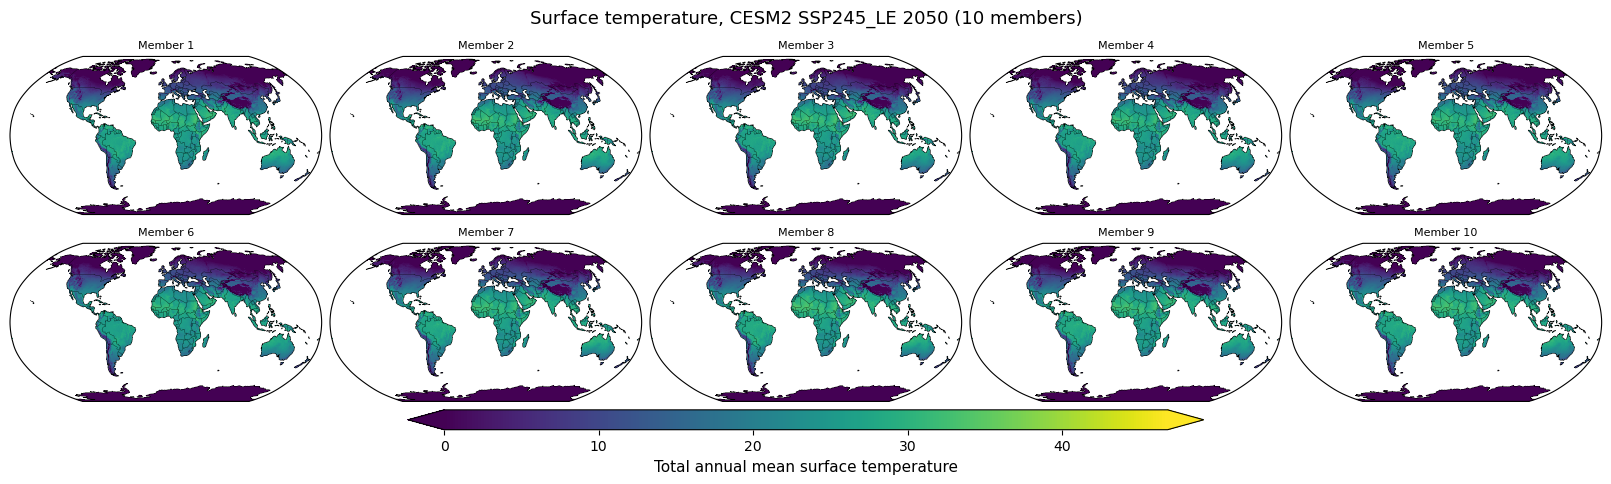

In [24]:
plot_mortality_ensemble_grid(standardise_latlon(da - 273.15), model, scenario, plotting_year,
                             member_dim="ensemble", cmap="viridis", borders=True,
                             SAVE_DIR=SAVE_DIR)

(<Figure size 1600x472 with 11 Axes>,
 array([<GeoAxes: title={'center': 'Member 1'}>,
        <GeoAxes: title={'center': 'Member 2'}>,
        <GeoAxes: title={'center': 'Member 3'}>,
        <GeoAxes: title={'center': 'Member 4'}>,
        <GeoAxes: title={'center': 'Member 5'}>,
        <GeoAxes: title={'center': 'Member 6'}>,
        <GeoAxes: title={'center': 'Member 7'}>,
        <GeoAxes: title={'center': 'Member 8'}>,
        <GeoAxes: title={'center': 'Member 9'}>,
        <GeoAxes: title={'center': 'Member 10'}>], dtype=object))

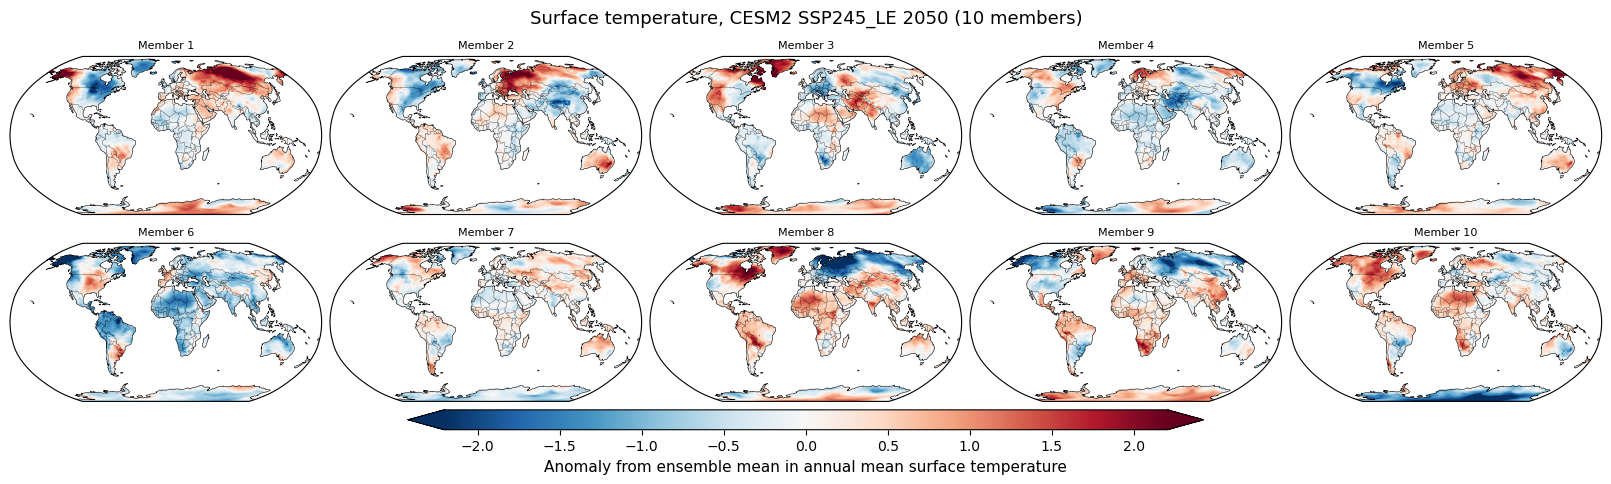

In [25]:
plot_mortality_ensemble_grid(standardise_latlon(da - 273.15), model, scenario, plotting_year,
                             anomaly=True, member_dim="ensemble", borders=True,
                             SAVE_DIR=SAVE_DIR)